# 03 · Evaluación operativa: simulación de inventario y políticas

Proyecto CityBykeNY (DataRush). El criterio de éxito no es el error de pronóstico sino cuántas
**horas de estación en riesgo** (estación casi vacía o casi llena) quedan en una simulación de
inventario, con un presupuesto fijo de bicis trasladadas por día. Se comparan tres políticas con
varios presupuestos.

Lenguaje: los datos solo registran **demanda atendida**. Los viajes bloqueados son un resultado
de la simulación (posible demanda insatisfecha), no demanda medida. Se habla de **riesgo simulado
evitado**.

## Cómo reproducir desde cero

Desde la raíz del repositorio, con el entorno activado (Python 3.12), en este orden:

```bash
python3.12 -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt -c constraints.txt

python scripts/download_trips.py --desde 202607 --hasta 202609   # unos 3 GB, a data/raw/trips
python scripts/freeze_gbfs.py            # SOLO si falta config/gbfs_congelado.csv (necesita una captura de GBFS)
python scripts/build_tables.py           # limpieza: stations, station_hour, routes y trips
python scripts/run_baseline.py           # promedio histórico: predictions y métricas de validación
python scripts/run_lgbm.py               # LightGBM con cuantiles: predictions y métricas de validación
python scripts/run_simulation.py         # simulación en validación: recommendations y policy_curve
python scripts/run_piso_wape.py          # piso del WAPE y métricas por franja, en validación
```

La prueba final **ya se usó, una sola vez, el 10 de octubre de 2026**, con la banda fijada en el
valor elegido en validación. Los comandos fueron
`python scripts/run_simulation.py --tramo prueba --usar-prueba-final --banda 0` y
`python scripts/run_prueba_final.py --usar-prueba-final`; escriben aparte, en
`data/processed/prueba_final/`. Este notebook no vuelve a simular nada.

Este notebook **no recalcula nada pesado**: lee `data/processed` y los reportes de
`data/processed/reports` que dejaron esos comandos, y muestra tablas y gráficas. El paso que corresponde a este notebook es `run_simulation.py` (`src/sim/`), con su reporte en `simulacion.md` y `simulacion.json`.
Para volver a ejecutarlo: `python -m jupyter nbconvert --to notebook --execute --inplace notebooks/03_evaluacion_y_simulacion.ipynb`.

In [1]:
# Raíz del repositorio: funciona si el notebook se abre desde notebooks/ o desde la raíz.
import json
import os
import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "paths.py").exists())
sys.path.insert(0, str(RAIZ))
os.chdir(RAIZ)  # las rutas relativas (config/, data/) se resuelven desde la raíz

import duckdb
import pandas as pd
from IPython.display import Markdown, display

from src.paths import DATA_PROCESSED, DATA_RAW, REPORTS, TZ

pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", None)


def leer_json(ruta):
    return json.loads(Path(ruta).read_text(encoding="utf-8"))


def miles(v, dec=0):
    return f"{v:,.{dec}f}"


def pct(v, dec=1):
    return f"{100 * v:.{dec}f} %"


print("Raíz:", RAIZ.name, "| zona horaria:", TZ)

Raíz: CityBykeNY | zona horaria: America/New_York


In [2]:
# Gráficas: el entorno del proyecto no trae matplotlib, así que se dibujan con Pillow
# y quedan como PNG dentro del notebook (se ven en GitHub sin ejecutar nada).
import io
import math

from IPython.display import Image as PNG
from PIL import Image, ImageDraw, ImageFont

TINTA, GRIS, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
AZUL, NARANJA, VERDE, NEUTRO = "#2a78d6", "#eb6834", "#1baf7a", "#898781"


def fuente(puntos):
    """Una fuente del sistema con acentos; si no hay ninguna, la de Pillow (que no los trae)."""
    for nombre in ("Arial.ttf", "DejaVuSans.ttf", "Helvetica.ttc", "LiberationSans-Regular.ttf", "arial.ttf"):
        try:
            return ImageFont.truetype(nombre, puntos)
        except OSError:
            continue
    return ImageFont.load_default(size=puntos)


def grafica(series, titulo, eje_x, eje_y, marcas_x, lineas_v=(), lineas_h=(), en_pct=False, ancho=860, alto=400):
    """Líneas sobre un solo eje que empieza en cero.

    series: lista de dicts con nombre, x, y, color y, si hay intervalo, bajo y alto.
    marcas_x: lista de (valor, texto). lineas_v y lineas_h: listas de (valor, texto).
    """
    k = 2  # se dibuja al doble para que se vea nítido
    W, H = ancho * k, alto * k
    img = Image.new("RGB", (W, H), FONDO)
    d = ImageDraw.Draw(img)
    f_t, f_n = fuente(15 * k), fuente(12 * k)
    izq, der, arr, aba = 80 * k, 30 * k, 84 * k, 58 * k
    xs = [float(v) for s in series for v in s["x"]]
    ys = [float(v) for s in series for c in ("y", "bajo", "alto") for v in s.get(c, [])] + [float(h) for h, _ in lineas_h]
    x0, x1, y1 = min(xs), max(xs), max(ys) * 1.08
    paso = 10 ** math.floor(math.log10(y1 / 4))
    paso *= next(m for m in (1, 2, 5, 10) if y1 / (paso * m) <= 6)
    px = lambda x: izq + (float(x) - x0) / (x1 - x0) * (W - izq - der)
    py = lambda y: H - aba - float(y) / y1 * (H - arr - aba)
    texto = (lambda v: f"{100 * v:.0f} %") if en_pct else (lambda v: f"{v:,.0f}" if paso >= 1 else f"{v:,.2f}")

    d.text((izq, 10 * k), titulo, fill=TINTA, font=f_t)
    lx = izq
    for s in series:
        d.line([(lx, 44 * k), (lx + 18 * k, 44 * k)], fill=s["color"], width=3 * k)
        d.text((lx + 24 * k, 36 * k), s["nombre"], fill=GRIS, font=f_n)
        lx += 24 * k + d.textlength(s["nombre"], font=f_n) + 22 * k
    d.text((izq, arr - 22 * k), eje_y, fill=GRIS, font=f_n)

    for i in range(int(y1 / paso) + 1):
        v = i * paso
        d.line([(izq, py(v)), (W - der, py(v))], fill=REJILLA if i else "#c3c2b7", width=k)
        t = texto(v)
        d.text((izq - 8 * k - d.textlength(t, font=f_n), py(v) - 8 * k), t, fill=GRIS, font=f_n)
    for v, t in marcas_x:
        d.line([(px(v), H - aba), (px(v), H - aba + 4 * k)], fill="#c3c2b7", width=k)
        d.text((px(v) - d.textlength(t, font=f_n) / 2, H - aba + 8 * k), t, fill=GRIS, font=f_n)
    d.text(((izq + W - der) / 2 - d.textlength(eje_x, font=f_n) / 2, H - 24 * k), eje_x, fill=GRIS, font=f_n)
    for v, t in lineas_v:
        d.line([(px(v), arr), (px(v), H - aba)], fill=NEUTRO, width=k)
        d.text((px(v) + 5 * k, arr + 2 * k), t, fill=GRIS, font=f_n)
    for v, t in lineas_h:
        d.line([(izq, py(v)), (W - der, py(v))], fill=NEUTRO, width=k)
        d.text((izq + 8 * k, py(v) + 5 * k), t, fill=GRIS, font=f_n)

    for i, s in enumerate(series):
        puntos = [(px(x), py(y)) for x, y in zip(s["x"], s["y"])]
        if "bajo" in s:  # intervalo: bigote vertical, corrido unos pixeles para que no se tapen entre series
            corr = (i - (len(series) - 1) / 2) * 5 * k
            for x, lo, hi in zip(s["x"], s["bajo"], s["alto"]):
                d.line([(px(x) + corr, py(lo)), (px(x) + corr, py(hi))], fill=s["color"], width=k)
                for y in (lo, hi):
                    d.line([(px(x) + corr - 3 * k, py(y)), (px(x) + corr + 3 * k, py(y))], fill=s["color"], width=k)
        if len(puntos) > 1:
            d.line(puntos, fill=s["color"], width=2 * k, joint="curve")
        if len(puntos) <= 31:
            for x, y in puntos:
                d.ellipse([x - 5 * k, y - 5 * k, x + 5 * k, y + 5 * k], fill=s["color"], outline=FONDO, width=k)

    salida = io.BytesIO()
    img.save(salida, format="PNG", optimize=True)
    display(PNG(data=salida.getvalue(), width=ancho))

## 1. Reglas de operación

El simulador no lleva números de operación escritos en el código: los lee de
`config/operacion.yaml` con `src.sim.operacion.load_operacion()`. Los fijó logística y su
justificación está en `docs/reglas_operacion.md`.

In [3]:
from src.sim.operacion import load_operacion

op = load_operacion()
sim = leer_json(REPORTS / "simulacion.json")
print(f"Estado: {op['estado']} por {op['confirmado_por']} el {op['fecha_confirmacion']}")
display(pd.DataFrame(op["franjas"]).set_index("nombre"))
u = op["umbral_riesgo"]
print(f"Una estación está en riesgo con menos de {u['bicis_minimas']} bicis o menos de {u['lugares_libres_minimos']} lugares libres.")
print(f"Distancia máxima de un traslado: {op['distancia_maxima_km']} km en línea recta.")
print(f"Presupuesto de referencia: {op['presupuesto_de_referencia']} bicis por estación por día.")

estaciones = sim["estaciones"]["simuladas"]
reparto = sim["reglas"]["reparto_por_franja"]
display(pd.DataFrame(
    [{"bicis por estación por día": p, f"bicis al día ({miles(estaciones)} estaciones)": miles(int(total)), **{f"de ellas, {k}": miles(v) for k, v in partes.items()}}
     for p, (total, partes) in zip(op["presupuestos_por_estacion"], reparto.items())]).set_index("bicis por estación por día"))
display(pd.DataFrame(
    {tipo: {"prioridad": e["prioridad"], **{f"ocupación de respaldo, {f}": v for f, v in e["ocupacion_respaldo"].items()}}
     for tipo, e in op["estrategia_por_tipo"].items()}).T.astype({"prioridad": int}))
v = op["excepciones_valet"]
print("Valet (en esas horas no se cuenta riesgo ni se asigna presupuesto):", ", ".join(v["estaciones"]), "| días:", ", ".join(v["dias"]))
print("Grupos aislados (solo intercambian bicis entre ellas):", op["grupos_aislados"])

Estado: confirmado por Rodrigo Gutiérrez el 2026-10-10


,momento_intervencion,inicio,fin,parte_del_presupuesto
nombre,,,,
manana,05:00,06:00,14:00,0.6
tarde,14:00,14:00,22:00,0.4


Una estación está en riesgo con menos de 2 bicis o menos de 3 lugares libres.
Distancia máxima de un traslado: 2.0 km en línea recta.
Presupuesto de referencia: 1.4 bicis por estación por día.


,"bicis al día (2,315 estaciones)","de ellas, manana","de ellas, tarde"
bicis por estación por día,,,
0.00,0,0,0
0.35,810,486,324
0.70,"1,620",972,648
1.40,"3,241","1,945","1,296"
2.60,"6,019","3,611","2,408"
4.30,"9,954","5,972","3,982"


,prioridad,"ocupación de respaldo, manana","ocupación de respaldo, tarde"
oficinas,3,0.1,0.90
residencial,3,0.9,0.15
recreativa,1,0.5,0.50
mixta,2,0.5,0.50


Valet (en esas horas no se cuenta riesgo ni se asigna presupuesto): 6492.08, 6584.12, 4804.02, 6822.09, 5288.08, 5470.12 | días: lunes, martes, miercoles, jueves, viernes
Grupos aislados (solo intercambian bicis entre ellas): {'governors_island': ['4631.02', '4440.02', '4374.01']}


## 2. Las tres políticas y las reglas del simulador

| Política | Qué hace |
|---|---|
| Sin intervención (`none`) | No mueve bicis. Es un sistema sin rebalanceo, no lo que el operador hizo de verdad esos días. |
| Regla histórica (`historical`) | Decide con el promedio histórico por estación, día de la semana y hora (la línea base). |
| Modelo (`model`) | Decide con el pronóstico de LightGBM. |

**Una sola maquinaria para las dos políticas con pronóstico; solo cambia el pronóstico.** Reglas
(`src/sim/engine.py`, `policies.py`, `simulate.py`):

- Las tres se califican con las mismas secuencias reales de viajes y el mismo inventario inicial.
  Ninguna ve viajes futuros.
- Simulación continua: el inventario pasa de un día al siguiente. El primer día es calentamiento:
  se simula y no cuenta.
- Una salida con inventario cero es un **viaje bloqueado**: se cuenta y no genera llegada. Una
  llegada a una estación llena se desvía a la estación con lugar más cercana.
- Un traslado respeta las bicis disponibles en el origen, el lugar en el destino, la distancia
  máxima y el presupuesto. El total de bicis se conserva.
- El presupuesto se reparte por franja; lo que no se usa pasa a la siguiente franja del mismo
  día, nunca al día siguiente.
- **Riesgo:** horas que cada estación pasa por debajo del umbral, las 24 horas. Es la métrica
  principal; los viajes bloqueados son secundarios.
- Capacidad e inventario inicial salen de `config/gbfs_congelado.csv`, una captura de GBFS del
  10 de octubre de 2026, no de los días simulados.

In [4]:
e = sim["estaciones"]
print(f"Corrida de validación: {sim['tramo']['dias_evaluados'][0]} a {sim['tramo']['dias_evaluados'][-1]} "
      f"({len(sim['tramo']['dias_evaluados'])} días evaluados; calentamiento: {', '.join(sim['tramo']['dias_de_calentamiento'])}).")
print(f"Estaciones simuladas: {miles(e['simuladas'])} de {miles(e['en_stations'])} "
      f"(fuera: {e['sin_capacidad']['estaciones']} sin capacidad y {e['inactivas']['estaciones']} sin viajes en el tramo).")
i = sim["inventario_inicial"]
print(f"Inventario inicial: {miles(i['bicis'])} bicis en {miles(i['bicis'] + i['lugares'])} anclajes (ocupación {pct(i['ocupacion_del_conjunto'])}).")
print(f"Intervalos: {pct(sim['intervalo']['nivel'], 0)}, por remuestreo de {sim['intervalo']['dias_remuestreados']} días completos "
      f"({miles(sim['intervalo']['remuestreos'])} remuestreos).")

Corrida de validación: 2026-09-02 a 2026-09-14 (13 días evaluados; calentamiento: 2026-09-01).
Estaciones simuladas: 2,315 de 2,398 (fuera: 42 sin capacidad y 41 sin viajes en el tramo).
Inventario inicial: 33,889 bicis en 104,110 anclajes (ocupación 48.3 %).
Intervalos: 90 %, por remuestreo de 13 días completos (2,000 remuestreos).


## 3. Curva de riesgo contra presupuesto, en validación

`policy_curve.parquet`: horas de estación en riesgo por día (promedio de los días evaluados)
para cada política y cada presupuesto diario de bicis, con su intervalo.

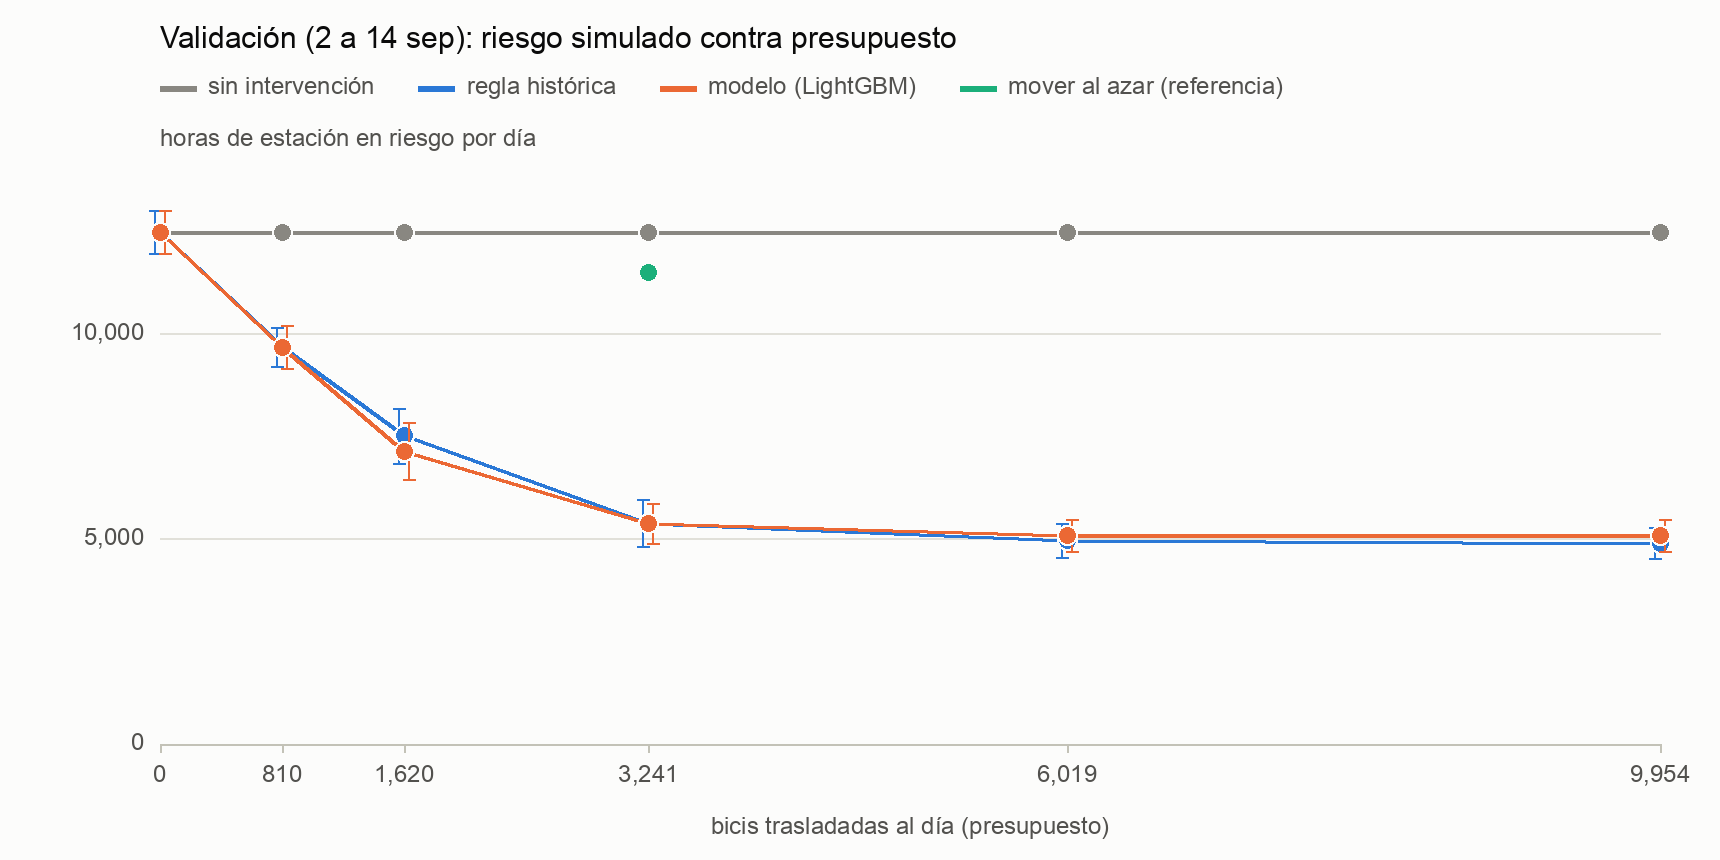

horas en riesgo por día                    intervalo del 90 %                     riesgo simulado evitado                  
política             regla histórica modelo (LightGBM)     regla histórica   modelo (LightGBM)         regla histórica modelo (LightGBM)
bicis al día                                                                                                                            
810                          9,680.5           9,674.3  9,202.2 a 10,154.3  9,155.4 a 10,197.9                  22.4 %            22.5 %
1,620                        7,517.4           7,139.8   6,845.1 a 8,166.8   6,436.9 a 7,839.5                  39.8 %            42.8 %
3,241                        5,374.9           5,367.4   4,808.0 a 5,963.5   4,887.8 a 5,862.7                  56.9 %            57.0 %
6,019                        4,948.9           5,082.7   4,540.9 a 5,376.0   4,701.5 a 5,483.4                  60.3 %            59.3 %
9,954                        4,890.3           5,082.7   4,519.8 a 5,281.1   4,701.5 a 5,483.4                  60.8 %            59.3 %

Sin intervención: 12,477.5 horas de estación en riesgo por día.


In [5]:
POLITICAS = {"none": "sin intervención", "historical": "regla histórica", "model": "modelo (LightGBM)"}
COLORES = {"none": NEUTRO, "historical": AZUL, "model": NARANJA}


def mostrar_curva(curva, detalle, titulo):
    base = curva.loc[curva["policy"] == "none", "risk_station_hours"].iloc[0]
    series = []
    for p in POLITICAS:
        c = curva[curva["policy"] == p].sort_values("budget")
        s = {"nombre": POLITICAS[p], "x": c["budget"], "y": c["risk_station_hours"], "color": COLORES[p]}
        if p != "none":
            s.update(bajo=c["ci_low"], alto=c["ci_high"])
        series.append(s)
    azar = detalle["azar"]["riesgo_por_dia"]["media"]
    series.append({"nombre": "mover al azar (referencia)", "x": [detalle["presupuesto_de_referencia_en_bicis"]], "y": [azar], "color": VERDE})
    presupuestos = sorted(curva["budget"].unique())
    grafica(series, titulo, "bicis trasladadas al día (presupuesto)", "horas de estación en riesgo por día",
            [(b, miles(b)) for b in presupuestos], alto=430)
    t = curva.assign(politica=curva["policy"].map(POLITICAS), evitado=1 - curva["risk_station_hours"] / base)
    tabla = pd.DataFrame({
        "horas en riesgo por día": t["risk_station_hours"].map(lambda v: miles(v, 1)),
        "intervalo del 90 %": [f"{miles(a, 1)} a {miles(b, 1)}" for a, b in zip(t["ci_low"], t["ci_high"])],
        "riesgo simulado evitado": t["evitado"].map(pct)})
    tabla.index = pd.MultiIndex.from_arrays([t["budget"].map(miles), t["politica"]], names=["bicis al día", "política"])
    display(tabla[t["policy"].to_numpy() != "none"].unstack("política").reindex([miles(b) for b in presupuestos if b > 0]))
    print(f"Sin intervención: {miles(base, 1)} horas de estación en riesgo por día.")


vyp = leer_json(REPORTS / "validacion_y_prueba.json")
curva_val = pd.read_parquet(DATA_PROCESSED / "policy_curve.parquet")
mostrar_curva(curva_val, vyp["detalle"]["validacion"], "Validación (2 a 14 sep): riesgo simulado contra presupuesto")

Lectura (validación):

- Con el presupuesto de referencia, cualquiera de las dos políticas con pronóstico evita más de
  la mitad del riesgo simulado.
- **Con el presupuesto de referencia el modelo no supera a la regla histórica**: las dos curvas
  se tocan y los intervalos se enciman.
- Con la mitad del presupuesto (1,620 bicis al día) el modelo queda con menos riesgo que la regla
  histórica; con el presupuesto siguiente o más queda con algo más.
- Pasada la referencia la curva se aplana: mover más bicis casi no reduce el riesgo.

## 4. La misma curva en la prueba final

Simulada **una sola vez**, el 10 de octubre de 2026, con todo congelado: mismas reglas, mismo
archivo de GBFS, mismas predicciones y la banda de incertidumbre fijada en el valor que se eligió
en validación (no se volvió a elegir).

Prueba final: 2026-09-16 a 2026-09-29 (14 días evaluados), 2,338 estaciones, banda 0.0 (fijada de antemano: sí).


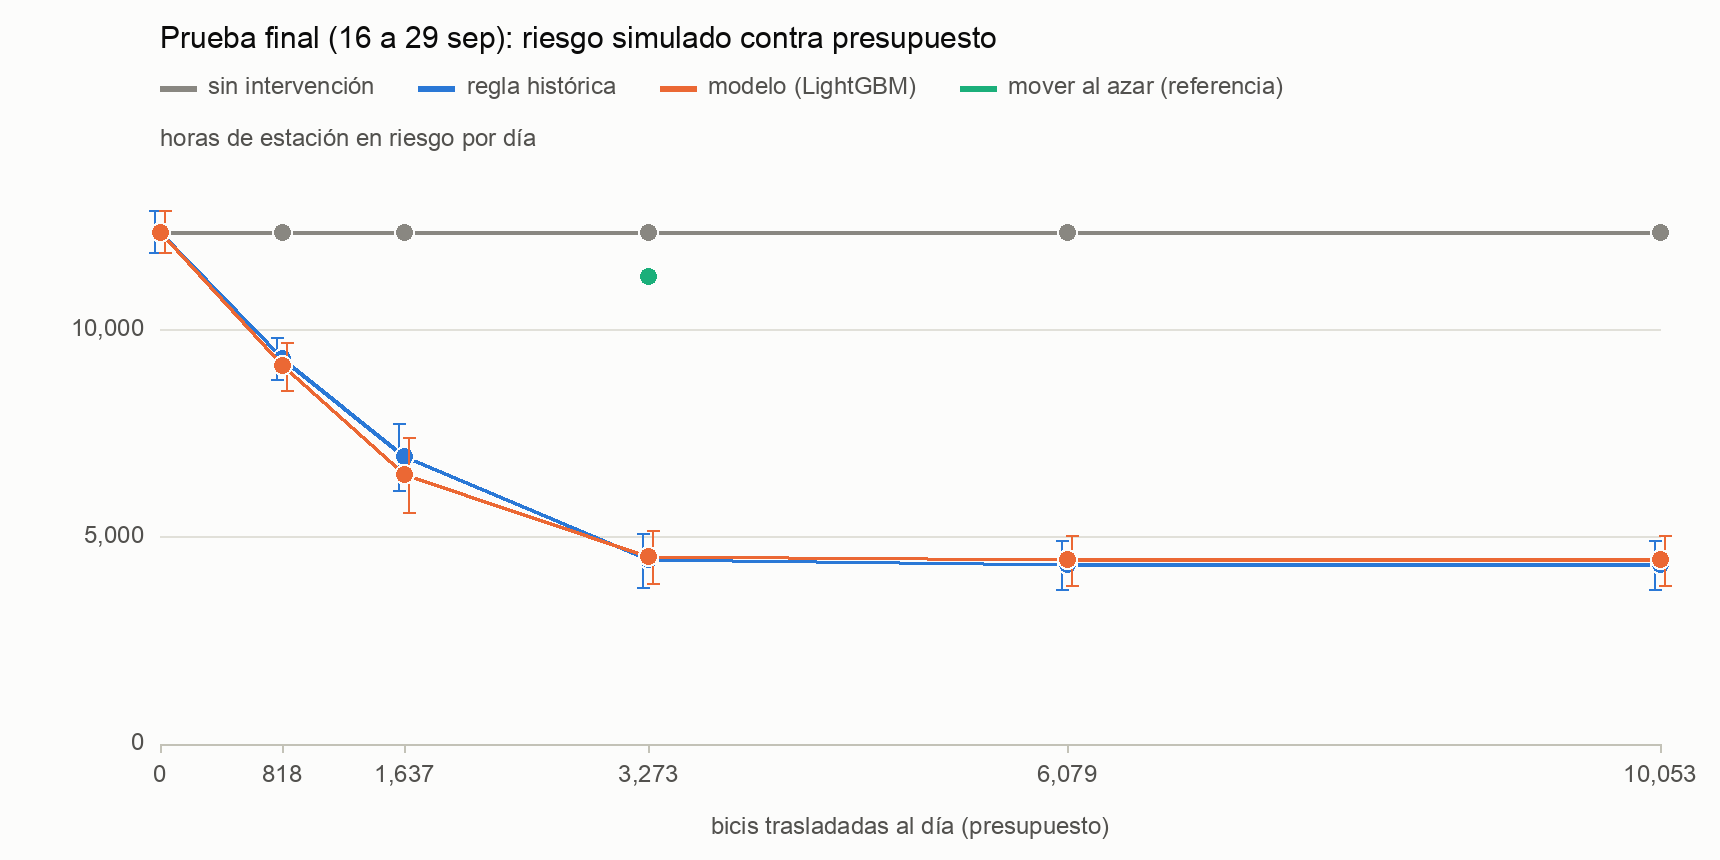

horas en riesgo por día                   intervalo del 90 %                    riesgo simulado evitado                  
política             regla histórica modelo (LightGBM)    regla histórica  modelo (LightGBM)         regla histórica modelo (LightGBM)
bicis al día                                                                                                                          
818                          9,319.5           9,148.4  8,794.2 a 9,824.9  8,542.1 a 9,696.3                  24.6 %            26.0 %
1,637                        6,944.5           6,516.5  6,124.2 a 7,732.3  5,596.6 a 7,391.4                  43.8 %            47.3 %
3,273                        4,448.1           4,534.4  3,788.3 a 5,083.4  3,881.5 a 5,165.3                  64.0 %            63.3 %
6,079                        4,342.9           4,450.3  3,731.2 a 4,924.9  3,838.6 a 5,037.0                  64.9 %            64.0 %
10,053                       4,342.9           4,450.3  3,731.2 a 4,924.9  3,838.6 a 5,037.0                  64.9 %            64.0 %

Sin intervención: 12,360.1 horas de estación en riesgo por día.


In [6]:
curva_pr = pd.read_parquet(DATA_PROCESSED / "prueba_final" / "policy_curve.parquet")
d = vyp["detalle"]["prueba"]
print(f"Prueba final: {d['primer_dia_evaluado']} a {d['ultimo_dia_evaluado']} ({d['dias_evaluados']} días evaluados), "
      f"{miles(d['estaciones_simuladas'])} estaciones, banda {d['banda']} (fijada de antemano: {'sí' if d['banda_fijada_de_antemano'] else 'no'}).")
mostrar_curva(curva_pr, d, "Prueba final (16 a 29 sep): riesgo simulado contra presupuesto")

In [7]:
# Validación contra prueba final: la tabla que lee el dashboard (filas de la simulación).
def valor(f, v, ic):
    if f["unidad"] == "pct":
        texto, rango = pct(v), ic and f"{pct(ic[0])} a {pct(ic[1])}"
    else:
        n = (lambda x: f"{x:+,.1f}") if f["clave"].startswith("diferencia") else (lambda x: miles(x, 1))
        texto, rango = n(v), ic and f"{n(ic[0])} a {n(ic[1])}"
    return f"{texto} ({rango})" if ic else texto


filas = [f for f in vyp["filas"] if not f["clave"].startswith(("wape_", "mae_", "cobertura_"))]
display(pd.DataFrame([{"afirmación": f["afirmacion"], "validación": valor(f, f["validacion"], f.get("validacion_ic")),
                       "prueba final": valor(f, f["prueba"], f.get("prueba_ic"))} for f in filas]).set_index("afirmación"))
dv, dp = vyp["detalle"]["validacion"], vyp["detalle"]["prueba"]
print(f"Días en que el modelo queda con menos riesgo que la regla histórica, presupuesto de referencia: "
      f"{dv['dias_modelo_con_menos_riesgo_referencia']} de {dv['dias_evaluados']} en validación y "
      f"{dp['dias_modelo_con_menos_riesgo_referencia']} de {dp['dias_evaluados']} en la prueba.")
print(f"Con la mitad del presupuesto: {dv['dias_modelo_con_menos_riesgo_1620']} de {dv['dias_evaluados']} y "
      f"{dp['dias_modelo_con_menos_riesgo_1620']} de {dp['dias_evaluados']}.")

,validación,prueba final
afirmación,,
"Riesgo simulado evitado con la regla histórica, presupuesto de referencia",56.9 % (52.8 % a 60.9 %),64.0 % (59.5 % a 68.8 %)
"Riesgo simulado evitado con el modelo, presupuesto de referencia",57.0 % (53.9 % a 60.1 %),63.3 % (58.9 % a 68.0 %)
"Horas de estación en riesgo por día, modelo menos regla histórica, presupuesto de referencia (negativo: el modelo tiene menos riesgo)",-7.5 (-194.9 a +129.5),+86.4 (+39.7 a +127.9)
"Horas de estación en riesgo por día, modelo menos regla histórica, con la mitad del presupuesto de referencia (1,620 bicis al día en validación; negativo: el modelo tiene menos riesgo)",-377.5 (-489.0 a -274.9),-428.0 (-649.0 a -212.6)
"Riesgo simulado evitado adicional (puntos porcentuales) al pasar del presupuesto de referencia al siguiente, regla histórica",3.4 % (1.3 % a 6.3 %),0.9 % (0.3 % a 1.7 %)
"Riesgo simulado evitado adicional (puntos porcentuales) al pasar del presupuesto de referencia al siguiente, modelo",2.3 % (0.9 % a 3.9 %),0.7 % (0.1 % a 1.4 %)
Riesgo simulado evitado moviendo las mismas bicis al azar,7.9 %,8.6 %
"Viajes bloqueados por día (simulados), sin intervención","4,983.2 (4,287.0 a 5,685.0)","4,168.7 (3,299.5 a 5,017.6)"
"Viajes bloqueados por día (simulados), regla histórica","3,424.9 (2,923.0 a 3,935.5)","2,698.1 (2,084.0 a 3,267.3)"


Días en que el modelo queda con menos riesgo que la regla histórica, presupuesto de referencia: 4 de 13 en validación y 2 de 14 en la prueba.
Con la mitad del presupuesto: 12 de 13 y 10 de 14.


Lectura (prueba final): se repite lo visto en validación. Con el presupuesto de referencia **el
modelo queda peor que la regla histórica** (más horas de estación en riesgo por día, con un
intervalo que no incluye el cero); con la mitad del presupuesto queda mejor. LightGBM tiene menos
error de pronóstico (notebook 02), pero un pronóstico con menos error no dio menos riesgo simulado
con el presupuesto de referencia. Entre paréntesis van intervalos del 90 % por remuestreo de
días; en las dos filas de "riesgo evitado adicional" la unidad son puntos porcentuales.

## 5. Mover al azar

Para saber cuánto riesgo se evita solo por mover bicis, sin saber a dónde, se simula una política
de referencia que gasta el mismo presupuesto moviendo bicis al azar (respeta origen, destino,
distancia y presupuesto). No es una de las tres políticas del contrato.

In [8]:
def fila_azar(d):
    a, base = d["azar"], d["riesgo_sin_intervencion_por_dia"]
    r = a["riesgo_por_dia"]
    return {"bicis al día": miles(d["presupuesto_de_referencia_en_bicis"]), "corridas": a["corridas"],
            "horas en riesgo por día (media)": miles(r["media"], 1), "rango entre corridas": f"{miles(r['minimo'], 1)} a {miles(r['maximo'], 1)}",
            "riesgo simulado evitado, azar": pct(1 - r["media"] / base),
            "regla histórica": pct(1 - d["riesgo_por_dia_historica"] / base), "modelo": pct(1 - d["riesgo_por_dia_modelo"] / base),
            "viajes bloqueados por día (simulados), azar": miles(a["viajes_bloqueados_por_dia"], 1)}


display(pd.DataFrame({"validación": fila_azar(dv), "prueba final": fila_azar(dp)}))

,validación,prueba final
bicis al día,"3,241","3,273"
corridas,5,5
horas en riesgo por día (media),"11,486.9","11,299.2"
rango entre corridas,"11,324.5 a 11,583.2","11,216.8 a 11,383.2"
"riesgo simulado evitado, azar",7.9 %,8.6 %
regla histórica,56.9 %,64.0 %
modelo,57.0 %,63.3 %
"viajes bloqueados por día (simulados), azar","5,083.9","4,262.5"


Mover las mismas bicis al azar evita cerca del 8 % del riesgo simulado, contra más de la mitad
con cualquiera de los dos pronósticos. El valor está en saber a dónde llevarlas; entre los dos
pronósticos la diferencia es pequeña.

## 6. Detalle en validación: franjas, banda e inventario inicial

In [9]:
ref = sim["reglas"]["presupuesto_de_referencia_en_bicis"]
res = {r["politica"]: r for r in sim["resultados"] if r["presupuesto_del_dia_en_bicis"] == ref}
print(f"Presupuesto de referencia ({miles(ref)} bicis al día), horas de estación en riesgo por día:")
t = pd.DataFrame({POLITICAS[p]: {**{f: r["riesgo_por_franja"][f]["media"] for f in ("manana", "tarde", "noche")},
                                 "total": r["riesgo_por_dia"]["media"],
                                 "por pocas bicis": r["riesgo_por_tipo"]["pocas_bicis"]["media"],
                                 "por pocos lugares": r["riesgo_por_tipo"]["pocos_lugares"]["media"],
                                 "bicis movidas por día": r["bicis_movidas"]["por_dia"],
                                 "viajes bloqueados por día (simulados)": r["viajes_bloqueados"]["por_dia"]} for p, r in res.items()})
display(t.rename(index={"manana": "mañana (06 a 14)", "tarde": "tarde (14 a 22)", "noche": "noche (22 a 06)"}).map(lambda v: miles(v, 1)))

print("Banda de incertidumbre (multiplicador de la dispersión del pronóstico), elegida en validación:")
display(pd.DataFrame([{"banda": b["banda"], "elegida": "sí" if b["elegida"] else "",
                       **{POLITICAS[p]: miles(x["riesgo_por_dia"], 1) for p, x in b["por_politica"].items()}}
                      for b in sim["banda"]["resultados"]]).set_index("banda"))

print("Sensibilidad al inventario inicial (presupuesto de referencia):")
display(pd.DataFrame([{"inventario inicial": f["inventario_inicial"], "bicis": miles(f["bicis"]),
                       "riesgo sin intervención por día": miles(f["riesgo_sin_intervencion_por_dia"], 1),
                       **{f"evitado, {POLITICAS[p]}": f"{x['riesgo_simulado_evitado_pct']:.1f} %" for p, x in f["por_politica"].items()}}
                      for f in sim["sensibilidad_al_inventario_inicial"]["filas"]]).set_index("inventario inicial"))

Presupuesto de referencia (3,241 bicis al día), horas de estación en riesgo por día:


,sin intervención,regla histórica,modelo (LightGBM)
mañana (06 a 14),"4,161.5","1,527.3","1,544.1"
tarde (14 a 22),"4,066.8","1,636.6","1,607.9"
noche (22 a 06),"4,249.2","2,210.9","2,215.4"
total,"12,477.5","5,374.9","5,367.4"
por pocas bicis,"4,904.6","2,519.0","2,488.0"
por pocos lugares,"7,572.9","2,855.9","2,879.4"
bicis movidas por día,0.0,"3,063.3","2,853.9"
viajes bloqueados por día (simulados),"4,983.2","3,424.9","3,476.7"


Banda de incertidumbre (multiplicador de la dispersión del pronóstico), elegida en validación:


,elegida,regla histórica,modelo (LightGBM)
banda,,,
0.0,sí,"5,374.9","5,367.4"
0.5,,"6,349.9","6,196.9"
1.0,,"8,415.6","8,587.5"


Sensibilidad al inventario inicial (presupuesto de referencia):


,bicis,riesgo sin intervención por día,"evitado, regla histórica","evitado, modelo (LightGBM)"
inventario inicial,,,,
observado en GBFS,"33,889","12,477.5",56.9 %,57.0 %
todas al 40 %,"28,166","7,033.4",39.5 %,39.4 %
todas al 50 %,"35,851","7,699.5",48.6 %,46.9 %
todas al 60 %,"42,055","10,592.8",47.5 %,47.1 %


- La noche no tiene intervención propia y aun así su riesgo simulado baja con las dos políticas:
  empieza con el inventario que dejó la intervención de la tarde.
- La banda elegida es 0 (decidir con el valor central). Se eligió con los mismos días de
  validación con que se reporta el resultado, así que el resultado de validación sale favorecido;
  por eso en la prueba entró fijada.
- **El resultado depende del inventario inicial**, que es un supuesto: según el arranque, el
  riesgo simulado evitado va de cerca de 40 % a 57 %.

## 7. Experimento descartado: corrección de mediodía

Se documenta también lo que no funcionó. El texto que sigue es `docs/experimento_mediodia.md`.
Son números de una versión anterior del simulador (otro presupuesto de referencia y otra banda)
y **no se recalcularon**: no son comparables con las tablas de arriba.

In [10]:
display(Markdown((RAIZ / "docs" / "experimento_mediodia.md").read_text(encoding="utf-8").replace("## Experimento", "#### Experimento")))

#### Experimento descartado: modelo con corrección de mediodía

Se probó una cuarta política, solo en validación: en la intervención de la
tarde, el pronóstico de cada estación se multiplicó por la razón entre lo
observado y lo pronosticado en la mañana de ese mismo día (suavizada con 5
viajes), por separado para salidas y llegadas. Con el presupuesto de
referencia (1,158 bicis al día) y la banda 0.5, horas de estación en riesgo
por día:

| Política | Riesgo por día | Mañana | Tarde | Noche (22 a 06) | Resto |
|---|---:|---:|---:|---:|---:|
| Sin intervención | 10,328.5 | 2,511.3 | 2,524.2 | 3,494.7 | 1,798.3 |
| Regla histórica | 4,757.7 | 1,002.0 | 1,100.6 | 1,826.2 | 828.8 |
| Modelo | 4,752.7 | 1,007.2 | 1,108.5 | 1,805.1 | 831.9 |
| Modelo con corrección de mediodía | 5,027.4 | 1,046.3 | 1,217.9 | 1,870.5 | 892.7 |

La corrección dio más riesgo que el modelo sin corregir en los 13 días
evaluados (274.7 horas al día en promedio) y se descartó. Son números de la
corrida del 10 de octubre de 2026, anteriores a cambios posteriores del
simulador; no se recalculan. El código queda como registro en
`notebooks/a/exp_mediodia.py`.


## 8. Limitaciones

- **Solo se conoce la demanda atendida.** Los viajes bloqueados son simulados (posible demanda
  insatisfecha), no demanda medida. Se reporta riesgo simulado evitado, nada más.
- **"Sin intervención" no es lo que pasó.** Los viajes no traen los traslados que el operador
  hizo esos días; la política sin intervención es un sistema sin rebalanceo.
- **Inventario inicial y capacidad son supuestos**: salen de una captura de GBFS de octubre de
  2026, no de los días simulados, y el resultado cambia con el inventario inicial (sección 6).
  El total de bicis no cambia durante la corrida.
- **Línea recta:** la distancia ignora ríos y puentes.
- **Sin camiones:** los traslados son instantáneos; no se modela el número de camiones, su
  capacidad ni su ruta. El único límite es el presupuesto de bicis.
- **Los días no son independientes** (el inventario pasa de un día al siguiente y son 13 y 14
  días): los intervalos son indicativos, no una garantía estadística.
- **El reparto** atiende primero la diferencia más pequeña; el reparto por riesgo evitado por
  bici no se implementó.
- **Valet:** con las horas de intervención de hoy (05:00 y 14:00) ningún intervalo de valet las
  contiene, así que la regla solo cambia la cuenta del riesgo.
- Bicis clásicas y eléctricas se cuentan juntas. Una estación cerrada varios días se ve como
  demanda cero.
- **Verificación:** la segunda versión del simulador no tiene una reimplementación independiente;
  solo sus pruebas con redes pequeñas y la conservación del total de bicis.
- **La prueba final ya se usó** (una vez, el 10 de octubre de 2026). Cualquier ajuste posterior
  se decide con validación.

La lista completa, con sus conteos, está al final de `data/processed/reports/simulacion.md`.